# Neuro IA Marketing — CNN de expresiones faciales
TensorFlow/Keras · Entrenamiento desde cero · Seis clases, sin miedo.

En VS Code selecciona **Seleccionar kernel → Entornos de Python → .venv** (Python 3.12).
Ejecuta las celdas en orden. La sección **Entrenar** inicia el entrenamiento real.
Las imágenes se leen desde `train` y `test`, sin moverlas ni modificarlas.
El 20 % de `train` se reserva para validación; `test` solo se usa al final.
Los resultados se guardan en `modelos/CNN_fecha_hora`.

La salida estima la clase de expresión facial; no demuestra el estado emocional interno de una persona.


In [1]:
from pathlib import Path
from collections import Counter
import sys
import numpy as np
import tensorflow as tf
from tensorflow import keras
from sklearn.model_selection import train_test_split

# Abre este notebook desde la raíz del proyecto.
BASE = Path.cwd()
if not (BASE / 'train').is_dir() or not (BASE / 'test').is_dir():
    raise FileNotFoundError(f'Abre la carpeta Neuro-IA-Marketing en VS Code. Ruta actual: {BASE}')
CLASES = ['angry', 'disgusted', 'happy', 'neutral', 'sad', 'surprised']
SEMILLA = 42
BATCH_SIZE = 32
EPOCAS = 80
keras.utils.set_random_seed(SEMILLA)
print('Python:', sys.version.split()[0], '| TensorFlow:', tf.__version__)
print('Intérprete:', sys.executable)
print('Proyecto:', BASE)
print('GPU detectadas:', tf.config.list_physical_devices('GPU'))


Python: 3.12.14 | TensorFlow: 2.21.0
Intérprete: C:\Users\Garcia\Desktop\Neuro-IA-Marketing\.venv\Scripts\python.exe
Proyecto: C:\Users\Garcia\Desktop\Neuro-IA-Marketing
GPU detectadas: []


## 1. Separar entrenamiento y validación
La división es estratificada y reproducible. `fearful`, si existe en test, se ignora.


In [2]:
def listar_imagenes(carpeta):
    rutas, etiquetas = [], []
    for etiqueta, clase in enumerate(CLASES):
        subcarpeta = carpeta / clase
        if not subcarpeta.is_dir():
            raise FileNotFoundError(f'Falta la carpeta: {subcarpeta}')
        archivos = sorted(p for p in subcarpeta.iterdir()
                          if p.is_file() and p.suffix.lower() in ('.png', '.jpg', '.jpeg'))
        if not archivos:
            raise ValueError(f'No hay imágenes en: {subcarpeta}')
        rutas.extend(str(p) for p in archivos)
        etiquetas.extend([etiqueta] * len(archivos))
    return rutas, etiquetas

rutas, etiquetas = listar_imagenes(BASE / 'train')
x_train, x_val, y_train, y_val = train_test_split(
    rutas, etiquetas, test_size=0.20, random_state=SEMILLA, stratify=etiquetas)
x_test, y_test = listar_imagenes(BASE / 'test')
assert set(x_train).isdisjoint(x_val)
assert (set(x_train) | set(x_val)).isdisjoint(x_test)
print(f"{'Clase':<12} {'Train':>7} {'Validación':>11} {'Test':>7}")
for i, clase in enumerate(CLASES):
    print(f'{clase:<12} {Counter(y_train)[i]:>7} {Counter(y_val)[i]:>11} {Counter(y_test)[i]:>7}')
print(f'Totales: train={len(x_train)}, validación={len(x_val)}, test={len(x_test)}')


Clase          Train  Validación    Test
angry           1050         263     958
disgusted       1050         263     111
happy           1001         250    1774
neutral         1001         250    1233
sad             1001         251    1263
surprised       1001         250     831
Totales: train=6104, validación=1527, test=6170


## 2. Cargar imágenes de 48 × 48, en escala de grises
Los píxeles se normalizan al intervalo [0, 1].


In [3]:
def leer_imagen(ruta, etiqueta):
    imagen = tf.io.decode_image(tf.io.read_file(ruta), channels=1, expand_animations=False)
    imagen = tf.ensure_shape(imagen, (None, None, 1))
    imagen = tf.image.resize(imagen, (48, 48))
    return tf.cast(imagen, tf.float32) / 255.0, etiqueta

def crear_dataset(rutas, etiquetas):
    ds = tf.data.Dataset.from_tensor_slices((rutas, etiquetas))
    return ds.map(leer_imagen, num_parallel_calls=tf.data.AUTOTUNE).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

train_ds = crear_dataset(x_train, y_train)
val_ds = crear_dataset(x_val, y_val)
test_ds = crear_dataset(x_test, y_test)
imagenes, etiquetas_lote = next(iter(train_ds))
print('Lote:', imagenes.shape, '| rango:', float(tf.reduce_min(imagenes)), float(tf.reduce_max(imagenes)))


Lote: (32, 48, 48, 1) | rango: 0.0 1.0


## 3. Crear la CNN
Pesos inicializados desde cero. Las transformaciones aleatorias y Dropout solo actúan al entrenar. Ejecutar esta celda de nuevo reinicia los pesos.


In [4]:
# Crear modelo: CNN pequeña, con pesos inicializados desde cero.
from tensorflow import keras
from tensorflow.keras import layers

keras.utils.set_random_seed(SEMILLA)
modelo = keras.Sequential([
    keras.Input(shape=(48, 48, 1)),
    layers.RandomFlip('horizontal', seed=SEMILLA),
    layers.RandomRotation(0.04, seed=SEMILLA + 1),
], name='cnn_expresiones')

for filtros in (16, 32, 64):
    modelo.add(layers.Conv2D(filtros, 3, padding='same', activation='relu'))
    modelo.add(layers.Conv2D(filtros, 3, padding='same', activation='relu'))
    modelo.add(layers.BatchNormalization())
    modelo.add(layers.MaxPooling2D())
    modelo.add(layers.Dropout(0.20))

modelo.add(layers.GlobalAveragePooling2D())
modelo.add(layers.Dense(64, activation='relu'))
modelo.add(layers.Dropout(0.30))
modelo.add(layers.Dense(len(CLASES), activation='softmax', name='emociones'))
modelo.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
modelo.summary()

# Verificación de entrada/salida; esto aún NO entrena la red.
lote, _ = next(iter(train_ds))
probabilidades = modelo(lote, training=False)
tf.debugging.assert_equal(tf.shape(probabilidades)[1], len(CLASES))
tf.debugging.assert_all_finite(probabilidades, 'Salida no válida')
tf.debugging.assert_near(tf.reduce_sum(probabilidades, axis=1), tf.ones(tf.shape(lote)[0]))
print('Red comprobada. Entrada:', lote.shape, '| salida:', probabilidades.shape)
print('Orden de salida:', dict(enumerate(CLASES)))


Model: "cnn_expresiones"
┌─────────────────────────────────┬────────────────────────┬───────────────┐
│ Layer (type)                    │ Output Shape           │       Param # │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 48, 48, 1)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 48, 48, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 48, 48, 16)     │         2,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 48, 48, 

## 4. Continuar entrenamiento hasta la época 80
Se carga el mejor modelo anterior, incluido su optimizador. Ese modelo corresponde
a la época 29; por eso la continuación comienza en la época 30 y puede llegar a la 80.
Se conserva la parada temprana de seis épocas sin mejora. Los resultados se guardan
en una carpeta nueva y el modelo anterior se mantiene intacto. Si no mejora la pérdida
de validación anterior, se conserva una copia del modelo anterior como mejor resultado.

Puedes ejecutar las secciones 1 y 2 y luego esta sección. Aunque ejecutes Crear la CNN,
esta celda volverá a cargar el modelo guardado; no empezará desde cero.


In [ ]:
# Entrenar: continuar desde el mejor modelo anterior hasta la época 80.
from datetime import datetime
import csv
import json
import shutil

EPOCAS = 80
ORIGEN = BASE / 'modelos' / 'CNN_20261013_190100_460557'
config_anterior = json.loads((ORIGEN / 'configuracion.json').read_text(encoding='utf-8'))
if config_anterior['clases'] != CLASES or config_anterior['semilla'] != SEMILLA:
    raise ValueError('Las clases o la semilla no coinciden con el entrenamiento anterior.')
with (ORIGEN / 'historial.csv').open(encoding='utf-8', newline='') as archivo:
    registros = list(csv.DictReader(archivo))
mejor = min(registros, key=lambda fila: float(fila['val_loss']))
EPOCA_INICIAL = int(mejor['epoch']) + 1
PERDIDA_ANTERIOR = float(mejor['val_loss'])
modelo = keras.models.load_model(ORIGEN / 'mejor_modelo.keras')

SALIDA = BASE / 'modelos' / datetime.now().strftime('CNN_80_%Y%m%d_%H%M%S_%f')
SALIDA.mkdir(parents=True, exist_ok=False)
shutil.copy2(ORIGEN / 'mejor_modelo.keras', SALIDA / 'mejor_modelo.keras')
(SALIDA / 'clases.json').write_text(json.dumps(CLASES, indent=2), encoding='utf-8')
# Mantener solo la historia que corresponde a los pesos recuperados.
with (SALIDA / 'historial.csv').open('w', encoding='utf-8', newline='') as archivo:
    escritor = csv.DictWriter(archivo, fieldnames=list(registros[0]))
    escritor.writeheader()
    escritor.writerows(fila for fila in registros if int(fila['epoch']) < EPOCA_INICIAL)
(SALIDA / 'configuracion.json').write_text(json.dumps({
    'clases': CLASES, 'semilla': SEMILLA, 'imagen': [48, 48, 1],
    'normalizacion': 'dividir por 255', 'epocas_maximas': EPOCAS,
    'epoca_inicial': EPOCA_INICIAL, 'modelo_origen': str(ORIGEN),
    'mejor_val_loss_anterior': PERDIDA_ANTERIOR, 'tensorflow': tf.__version__
}, indent=2), encoding='utf-8')

# Declarar el número exacto de imágenes evita cardinalidad desconocida al desagrupar.
train_fit = train_ds.unbatch().apply(
    tf.data.experimental.assert_cardinality(len(x_train))
).cache().shuffle(len(x_train), seed=SEMILLA, reshuffle_each_iteration=True
).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
val_fit = val_ds.cache().prefetch(tf.data.AUTOTUNE)

callbacks = [
    keras.callbacks.ModelCheckpoint(str(SALIDA / 'mejor_modelo.keras'),
        monitor='val_loss', mode='min', save_best_only=True,
        initial_value_threshold=PERDIDA_ANTERIOR),
    keras.callbacks.EarlyStopping(monitor='val_loss', patience=6,
        restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5,
        patience=2, min_lr=0.00001),
    keras.callbacks.CSVLogger(str(SALIDA / 'historial.csv'), append=True),
    keras.callbacks.TerminateOnNaN(),
]
print('Modelo recuperado de la época:', EPOCA_INICIAL)
print('Continuar hasta:', EPOCAS, '| Mejor pérdida anterior:', PERDIDA_ANTERIOR)
print('Archivos del entrenamiento:', SALIDA)
historial = modelo.fit(train_fit, validation_data=val_fit,
    initial_epoch=EPOCA_INICIAL, epochs=EPOCAS, shuffle=False, callbacks=callbacks)
modelo = keras.models.load_model(SALIDA / 'mejor_modelo.keras')
print('Mejor modelo cargado:', SALIDA / 'mejor_modelo.keras')


## 5. Revisar curvas de entrenamiento y validación


In [ ]:
# Ver el historial combinado después de terminar la continuación.
import csv
import matplotlib.pyplot as plt

if 'historial' not in globals():
    raise RuntimeError('Primero ejecuta la celda Entrenar y espera a que termine.')
with (SALIDA / 'historial.csv').open(encoding='utf-8', newline='') as archivo:
    filas = list(csv.DictReader(archivo))
epocas = [int(fila['epoch']) + 1 for fila in filas]
fig, ejes = plt.subplots(1, 2, figsize=(11, 4))
for eje, metrica, titulo in zip(ejes, ['accuracy', 'loss'], ['Exactitud', 'Pérdida']):
    eje.plot(epocas, [float(f[metrica]) for f in filas], label='Entrenamiento')
    eje.plot(epocas, [float(f['val_' + metrica]) for f in filas], label='Validación')
    eje.axvline(EPOCA_INICIAL + 0.5, color='gray', linestyle='--', label='Continuación')
    eje.set(title=titulo, xlabel='Época')
    eje.legend()
    eje.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(SALIDA / 'curvas.png', dpi=150)
plt.show()


## 6. Diagnosticar el modelo anterior con validación
Ejecuta primero la configuración y las secciones 1 y 2. No hace falta repetir el entrenamiento anterior.
Se usa el mejor checkpoint de la continuación. La matriz muestra proporciones por clase real:
las filas son etiquetas reales y las columnas predicciones. Se guardan también precisión, recall,
F1 y las confusiones más frecuentes. Esta sección no utiliza test.

CNN_original: accuracy=62.93%, loss=0.9967, macro F1=0.6325
              precision    recall  f1-score   support

       angry      0.406     0.494     0.446       263
   disgusted      0.849     0.772     0.809       263
       happy      0.762     0.728     0.744       250
     neutral      0.531     0.540     0.536       250
         sad      0.519     0.442     0.477       251
   surprised      0.766     0.800     0.783       250

    accuracy                          0.629      1527
   macro avg      0.639     0.629     0.633      1527
weighted avg      0.639     0.629     0.632      1527

Confusiones más frecuentes (real -> predicción):
  sad -> angry: 69 imágenes
  sad -> neutral: 43 imágenes
  neutral -> angry: 43 imágenes
  angry -> neutral: 43 imágenes
  angry -> sad: 38 imágenes
Diagnóstico guardado en: C:\Users\Garcia\Desktop\Neuro-IA-Marketing\modelos\Diagnostico_20261013_192050_467793


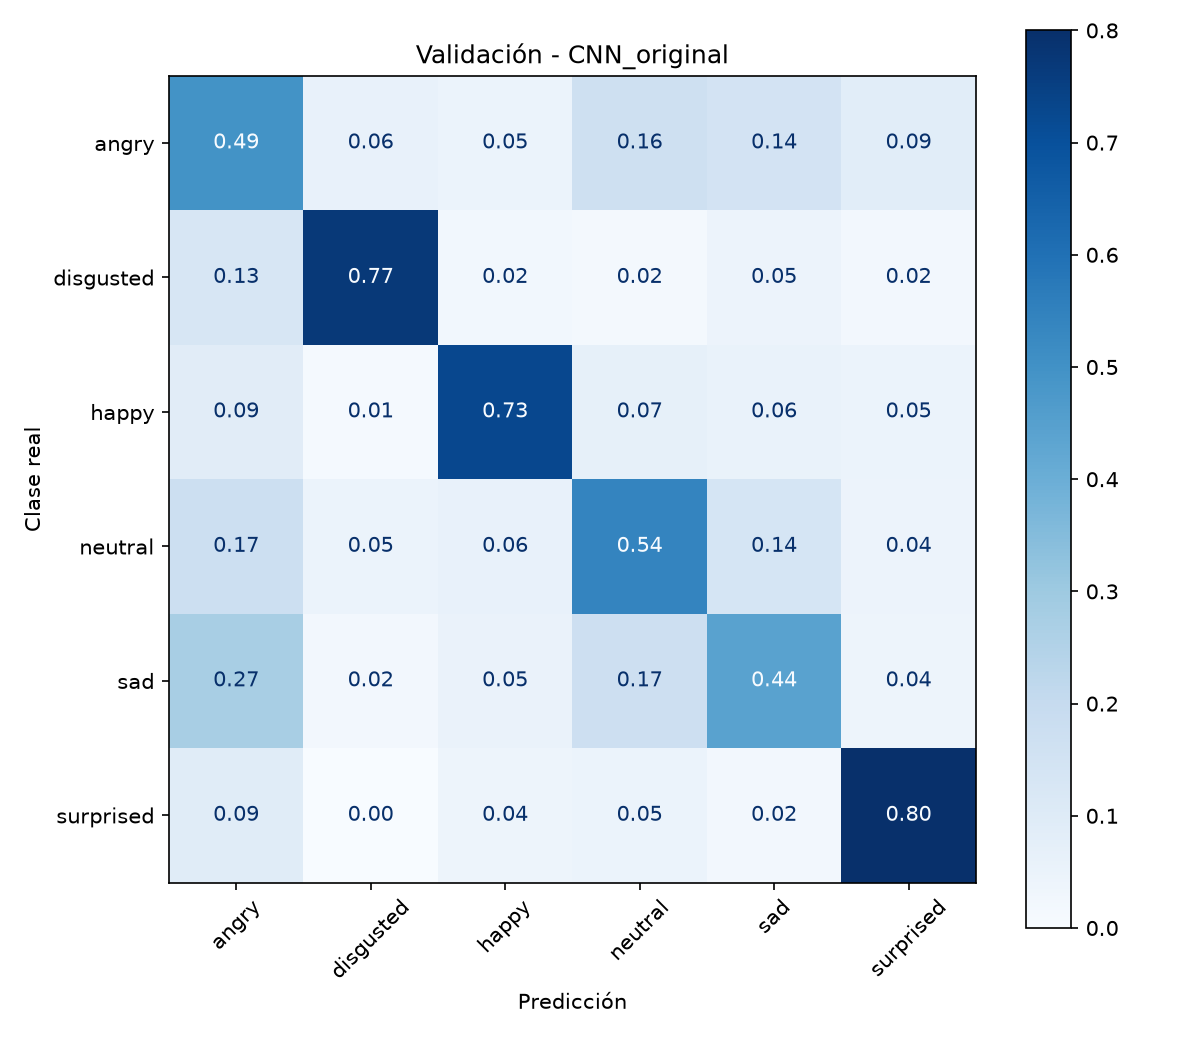

In [4]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
from datetime import datetime
import json

BASELINE_DIR = BASE / 'modelos' / 'CNN_80_20261013_191422_021766'
if json.loads((BASELINE_DIR / 'clases.json').read_text(encoding='utf-8')) != CLASES:
    raise ValueError('No coincide el orden de clases del modelo anterior.')
DIAGNOSTICO = BASE / 'modelos' / datetime.now().strftime('Diagnostico_%Y%m%d_%H%M%S_%f')
DIAGNOSTICO.mkdir(parents=True, exist_ok=False)

def evaluar_validacion(modelo_eval, nombre, carpeta):
    metricas = modelo_eval.evaluate(val_ds, return_dict=True, verbose=0)
    pred = np.argmax(modelo_eval.predict(val_ds, verbose=0), axis=1)
    reporte = classification_report(y_val, pred, labels=list(range(len(CLASES))),
        target_names=CLASES, output_dict=True, zero_division=0)
    resumen = {'modelo': nombre, 'val_loss': float(metricas['loss']),
        'val_accuracy': float(metricas['accuracy']), 'macro_f1': float(reporte['macro avg']['f1-score'])}
    print(f"{nombre}: accuracy={resumen['val_accuracy']:.2%}, loss={resumen['val_loss']:.4f}, macro F1={resumen['macro_f1']:.4f}")
    texto = classification_report(y_val, pred, labels=list(range(len(CLASES))),
        target_names=CLASES, digits=3, zero_division=0)
    print(texto)
    (carpeta / (nombre + '_reporte.txt')).write_text(texto, encoding='utf-8')
    (carpeta / (nombre + '_metricas.json')).write_text(json.dumps({'resumen': resumen, 'clases': reporte}, indent=2), encoding='utf-8')
    matriz = confusion_matrix(y_val, pred, labels=list(range(len(CLASES))))
    errores = sorted([(int(matriz[i, j]), CLASES[i], CLASES[j])
        for i in range(len(CLASES)) for j in range(len(CLASES)) if i != j], reverse=True)
    print('Confusiones más frecuentes (real -> predicción):')
    for cantidad, real, estimada in errores[:5]:
        print(f'  {real} -> {estimada}: {cantidad} imágenes')
    fig, ax = plt.subplots(figsize=(8, 7))
    ConfusionMatrixDisplay.from_predictions(y_val, pred, labels=list(range(len(CLASES))),
        display_labels=CLASES, normalize='true', values_format='.2f', cmap='Blues',
        xticks_rotation=45, ax=ax)
    ax.set(title=f'Validación - {nombre}', xlabel='Predicción', ylabel='Clase real')
    fig.tight_layout()
    fig.savefig(carpeta / (nombre + '_matriz_validacion.png'), dpi=150)
    plt.show()
    plt.close(fig)
    return resumen

modelo_anterior = keras.models.load_model(BASELINE_DIR / 'mejor_modelo.keras')
metricas_anterior = evaluar_validacion(modelo_anterior, 'CNN_original', DIAGNOSTICO)
print('Diagnóstico guardado en:', DIAGNOSTICO)

## 7. Crear CNN V2 desde cero
Se prueban bloques de 32, 64 y 128 filtros y una capa densa de 128 unidades.
Flatten conserva por separado las posiciones del último mapa de características,
en lugar de promediarlas como hacía la CNN original. Se mantienen entrada de 48×48,
seis clases, transformaciones suaves y pesos sin preentrenar.

Es una hipótesis a comprobar: más capacidad también puede aumentar el sobreajuste.
La división train/validación, la semilla y la normalización se mantienen iguales.

In [5]:
from tensorflow.keras import layers

def crear_modelo_v2():
    keras.utils.set_random_seed(SEMILLA)
    red = keras.Sequential([
        keras.Input(shape=(48, 48, 1)),
        layers.RandomFlip('horizontal', seed=SEMILLA),
        layers.RandomRotation(0.04, seed=SEMILLA + 1),
    ], name='cnn_expresiones_v2')
    for filtros in (32, 64, 128):
        red.add(layers.Conv2D(filtros, 3, padding='same', activation='relu'))
        red.add(layers.Conv2D(filtros, 3, padding='same', activation='relu'))
        red.add(layers.BatchNormalization())
        red.add(layers.MaxPooling2D())
        red.add(layers.Dropout(0.20))
    red.add(layers.Flatten())
    red.add(layers.Dense(128, activation='relu'))
    red.add(layers.Dropout(0.30))
    red.add(layers.Dense(len(CLASES), activation='softmax', name='emociones'))
    red.compile(optimizer=keras.optimizers.Adam(0.001),
        loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return red

modelo_v2 = crear_modelo_v2()
modelo_v2.summary()
print('Entrada:', modelo_v2.input_shape, '| salida:', modelo_v2.output_shape)

Model: "cnn_expresiones_v2"
┌─────────────────────────────────┬────────────────────────┬───────────────┐
│ Layer (type)                    │ Output Shape           │       Param # │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 48, 48, 1)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 48, 48, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 48, 48, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 48, 4

## 8. Entrenar CNN V2
Hasta 80 épocas desde cero. Se mantienen el optimizador inicial, la parada temprana
de seis épocas y la reducción de tasa cada dos épocas sin mejora, como en la primera prueba.
Cada ejecución de esta celda reinicia V2 y guarda una carpeta nueva; no sobrescribe la CNN anterior.

In [ ]:
import json
from datetime import datetime

modelo_v2 = crear_modelo_v2()
SALIDA_V2 = BASE / 'modelos' / datetime.now().strftime('CNN_V2_%Y%m%d_%H%M%S_%f')
SALIDA_V2.mkdir(parents=True, exist_ok=False)
(SALIDA_V2 / 'clases.json').write_text(json.dumps(CLASES, indent=2), encoding='utf-8')
(SALIDA_V2 / 'configuracion.json').write_text(json.dumps({
    'clases': CLASES, 'semilla': SEMILLA, 'imagen': [48, 48, 1],
    'normalizacion': 'dividir por 255', 'epocas_maximas': 80,
    'arquitectura': 'CNN_V2_32_64_128_Flatten_Dense128',
    'tensorflow': tf.__version__
}, indent=2), encoding='utf-8')
np.savez(SALIDA_V2 / 'division_datos.npz', x_train=np.array(x_train), y_train=np.array(y_train),
    x_val=np.array(x_val), y_val=np.array(y_val))
train_v2 = train_ds.unbatch().apply(tf.data.experimental.assert_cardinality(len(x_train))
    ).cache().shuffle(len(x_train), seed=SEMILLA, reshuffle_each_iteration=True
    ).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
val_v2 = val_ds.cache().prefetch(tf.data.AUTOTUNE)
callbacks_v2 = [
    keras.callbacks.ModelCheckpoint(str(SALIDA_V2 / 'mejor_modelo.keras'),
        monitor='val_loss', mode='min', save_best_only=True),
    keras.callbacks.EarlyStopping(monitor='val_loss', patience=6, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=0.00001),
    keras.callbacks.CSVLogger(str(SALIDA_V2 / 'historial.csv')),
    keras.callbacks.TerminateOnNaN(),
]
print('Entrenamiento desde cero. Resultados:', SALIDA_V2)
historial_v2 = modelo_v2.fit(train_v2, validation_data=val_v2,
    epochs=80, shuffle=False, callbacks=callbacks_v2)
modelo_v2 = keras.models.load_model(SALIDA_V2 / 'mejor_modelo.keras')
print('Mejor V2 cargada:', SALIDA_V2 / 'mejor_modelo.keras')

## 9. Comparar ambos modelos con validación
Ejecuta después de terminar V2. Se comparan los dos checkpoints con los mismos 1527 ejemplos.
El criterio de selección sigue siendo menor pérdida de validación; se muestran también accuracy
y macro F1 para revisar diferencias entre clases. Test todavía no interviene.

In [ ]:
import csv

if 'SALIDA_V2' not in globals() or not (SALIDA_V2 / 'mejor_modelo.keras').is_file():
    raise RuntimeError('Primero termina el entrenamiento V2.')
modelo_anterior = keras.models.load_model(BASELINE_DIR / 'mejor_modelo.keras')
modelo_v2 = keras.models.load_model(SALIDA_V2 / 'mejor_modelo.keras')
metricas_anterior = evaluar_validacion(modelo_anterior, 'CNN_original', SALIDA_V2)
metricas_v2 = evaluar_validacion(modelo_v2, 'CNN_V2', SALIDA_V2)
comparacion = [metricas_anterior, metricas_v2]
print(f"{'Modelo':<15} {'Accuracy':>10} {'Loss':>10} {'Macro F1':>10}")
for fila in comparacion:
    print(f"{fila['modelo']:<15} {fila['val_accuracy']:>10.2%} {fila['val_loss']:>10.4f} {fila['macro_f1']:>10.4f}")
with (SALIDA_V2 / 'comparacion_validacion.csv').open('w', encoding='utf-8', newline='') as archivo:
    escritor = csv.DictWriter(archivo, fieldnames=list(comparacion[0]))
    escritor.writeheader()
    escritor.writerows(comparacion)
CARPETA_ELEGIDA = SALIDA_V2 if metricas_v2['val_loss'] < metricas_anterior['val_loss'] else BASELINE_DIR
print('Elegido por menor pérdida de validación:', CARPETA_ELEGIDA / 'mejor_modelo.keras')

fig, ejes = plt.subplots(1, 2, figsize=(11, 4))
for eje, metrica, titulo in zip(ejes, ['accuracy', 'loss'], ['Exactitud V2', 'Pérdida V2']):
    epocas_v2 = range(1, len(historial_v2.history[metrica]) + 1)
    eje.plot(epocas_v2, historial_v2.history[metrica], label='Entrenamiento')
    eje.plot(epocas_v2, historial_v2.history['val_' + metrica], label='Validación')
    eje.set(title=titulo, xlabel='Época')
    eje.legend()
    eje.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(SALIDA_V2 / 'curvas_v2.png', dpi=150)
plt.show()

## 10. Evaluación final con test
Ejecuta solo después de terminar de seleccionar el modelo. Usa el checkpoint elegido en la sección 9. No ajustes los modelos basándote repetidamente en test.

In [ ]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

if 'CARPETA_ELEGIDA' not in globals() or not (CARPETA_ELEGIDA / 'mejor_modelo.keras').is_file():
    raise RuntimeError('Primero completa la comparación de validación (sección 9).')
modelo_final = keras.models.load_model(CARPETA_ELEGIDA / 'mejor_modelo.keras')
metricas = modelo_final.evaluate(test_ds, return_dict=True)
predicciones = np.argmax(modelo_final.predict(test_ds, verbose=0), axis=1)
reporte = classification_report(y_test, predicciones, labels=list(range(len(CLASES))),
                                target_names=CLASES, digits=3, zero_division=0)
print(metricas)
print(reporte)
(SALIDA_V2 / 'evaluacion_test.json').write_text(json.dumps(metricas, indent=2), encoding='utf-8')
(SALIDA_V2 / 'reporte_test.txt').write_text(reporte, encoding='utf-8')
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay.from_predictions(y_test, predicciones, labels=list(range(len(CLASES))),
    display_labels=CLASES, cmap='Blues', xticks_rotation=45, ax=ax)
fig.tight_layout()
fig.savefig(SALIDA_V2 / 'matriz_confusion.png', dpi=150)
plt.show()
